In [490]:
# Imports
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import re
import seaborn as sns


In [491]:
# Read in csv files
GT_df = pd.read_csv('data/weight_files/GT_weights.csv')

LG_df = pd.read_csv('data/weight_files/LG_weights.csv')
TRF_df = pd.read_csv('data/weight_files/TRF_weights.csv')

spotlight_df = pd.read_csv('data/weight_files/spotlight_weights.csv')

relik_df = pd.read_csv('data/weight_files/relik_weights.csv')
relik_cie_df = pd.read_csv('data/weight_files/relik_cie_weights.csv')

In [492]:
def extract_name(name):
    name = re.sub(r'_[a-z]{2}$', '', name)  
    name = name.replace('_', ' ') 
    name = name.replace("'", "") 
    return name.replace(',', '')                

In [493]:
relik_df['name'] = relik_df['name'].apply(extract_name)
relik_cie_df['name'] = relik_cie_df['name'].apply(extract_name)

## Map names to IDs

In [494]:
merged = GT_df.merge(LG_df, on='name').merge(TRF_df, on='name').merge(relik_df, on='name').merge(relik_cie_df, on='name').merge(spotlight_df, left_on='ID', right_on='source_wikidata_id')

In [495]:
merged = merged.drop(['name', 'source_wikidata_id', 'target_wikidata_id', 'language_code'], axis=1)
merged = merged.rename(columns={"ID": "source_ID", "weight": "spotlight_weight"})
merged.insert(1, 'target_ID', 'Q517')

In [496]:
merged.head()

,source_ID,target_ID,GT_weight,LG_weight,TRF_weight,relik_weight,relik_cie_weight,spotlight_weight
0,Q9068,Q517,1,1,1,0,3,1
1,Q360481,Q517,13,6,7,6,13,7
2,Q162296,Q517,2,2,2,2,5,2
3,Q354477,Q517,0,0,0,0,0,2
4,Q68771,Q517,0,0,0,0,16,3


In [497]:
merged.shape

(46, 8)

In [498]:
merged.isna().sum()

source_ID           0
target_ID           0
GT_weight           0
LG_weight           0
TRF_weight          0
relik_weight        0
relik_cie_weight    0
spotlight_weight    0
dtype: int64

In [499]:
# Read in napoleon csv files
GT_napoleon_df = pd.read_csv('data/weight_files/napoleon_out_edges/GT_napoleon_weights.csv')

LG_napoleon_df = pd.read_csv('data/weight_files/napoleon_out_edges/LG_napoleon_weights.csv')
TRF_napoleon_df = pd.read_csv('data/weight_files/napoleon_out_edges/TRF_napoleon_weights.csv')
relik_napoleon_df = pd.read_csv('data/weight_files/napoleon_out_edges/relik_napoleon_weights.csv')
relik_cie_napoleon_df = pd.read_csv('data/weight_files/napoleon_out_edges/relik_cie_napoleon_weights.csv')
spotlight_napoleon_df = pd.read_csv('data/weight_files/napoleon_out_edges/spotlight_napoleon_weights.csv')

TRF_napoleon_df.head()

,source_ID,target_ID,TRF_weight
0,Q517,Q7723,241
1,Q517,Q7721,241
2,Q517,Q7726,91
3,Q517,Q157521,85
4,Q517,Q151098,85


In [500]:
GT_napoleon_df = GT_napoleon_df.drop('Name', axis=1)
GT_napoleon_df = GT_napoleon_df.rename(columns={"ID": "target_ID"})
GT_napoleon_df.insert(0, 'source_ID', 'Q517')
GT_napoleon_df.head()

,source_ID,target_ID,GT_weight
0,Q517,Q15193,14
1,Q517,Q124754,13
2,Q517,Q7723,12
3,Q517,Q171480,12
4,Q517,Q7726,11


In [501]:
print(LG_napoleon_df.shape)
print(TRF_napoleon_df.shape)
print(relik_napoleon_df.shape)
print(relik_cie_napoleon_df.shape)
print(spotlight_napoleon_df.shape)
print(GT_napoleon_df.shape)

(403, 3)
(403, 3)
(403, 3)
(403, 3)
(403, 4)
(105, 3)


In [502]:
merged_napoleon = (
    LG_napoleon_df
    .merge(TRF_napoleon_df, on=['source_ID', 'target_ID'])  
    .merge(relik_napoleon_df, on=['source_ID', 'target_ID'])
    .merge(relik_cie_napoleon_df, on=['source_ID', 'target_ID'])
    .merge(spotlight_napoleon_df, on=['source_ID', 'target_ID'])    
    .merge(GT_napoleon_df,  on=['source_ID', 'target_ID'], how='left')
)
merged_napoleon['GT_weight'] = merged_napoleon['GT_weight'].fillna(0).astype(int)

merged_napoleon.head()

,source_ID,target_ID,LG_weight,TRF_weight,relik_weight,relik_cie_weight,language_code,spotlight_weight,GT_weight
0,Q517,Q7721,218,241,48,3,en,0,2
1,Q517,Q7723,216,241,2,4,en,0,12
2,Q517,Q7726,89,91,3,7,en,1,11
3,Q517,Q157521,83,85,0,0,en,0,0
4,Q517,Q151098,82,85,3,3,en,0,3


In [503]:
merged_napoleon = merged_napoleon.drop('language_code', axis=1)
merged_napoleon.head()

,source_ID,target_ID,LG_weight,TRF_weight,relik_weight,relik_cie_weight,spotlight_weight,GT_weight
0,Q517,Q7721,218,241,48,3,0,2
1,Q517,Q7723,216,241,2,4,0,12
2,Q517,Q7726,89,91,3,7,1,11
3,Q517,Q157521,83,85,0,0,0,0
4,Q517,Q151098,82,85,3,3,0,3


In [504]:
merged_napoleon.shape

(403, 8)

In [505]:
merged.isna().sum()

source_ID           0
target_ID           0
GT_weight           0
LG_weight           0
TRF_weight          0
relik_weight        0
relik_cie_weight    0
spotlight_weight    0
dtype: int64

In [506]:
final_merged = pd.concat(
    [merged, merged_napoleon],
    ignore_index=True
)
final_merged

,source_ID,target_ID,GT_weight,LG_weight,TRF_weight,relik_weight,relik_cie_weight,spotlight_weight
0,Q9068,Q517,1,1,1,0,3,1
1,Q360481,Q517,13,6,7,6,13,7
2,Q162296,Q517,2,2,2,2,5,2
3,Q354477,Q517,0,0,0,0,0,2
4,Q68771,Q517,0,0,0,0,16,3
...,...,...,...,...,...,...,...,...
444,Q517,Q151707,0,0,0,0,0,0
445,Q517,Q109240,0,0,0,0,0,0
446,Q517,Q464513,0,0,0,0,0,0
447,Q517,Q455181,0,0,0,0,0,0


## Compare ground truth to predictions

### Raw values

In [507]:
models = [
    ('spotlight_weight', 'Spotlight'),
    ('LG_weight', 'lg'),
    ('TRF_weight', 'trf'),
    ('relik_weight', 'Relik')
]

for (col, label) in models:
    err = merged[col] - merged['GT_weight']

    print(f'MAE for {label} {err.abs().mean():.1f}')


MAE for Spotlight 1.5
MAE for lg 1.8
MAE for trf 1.9
MAE for Relik 1.8


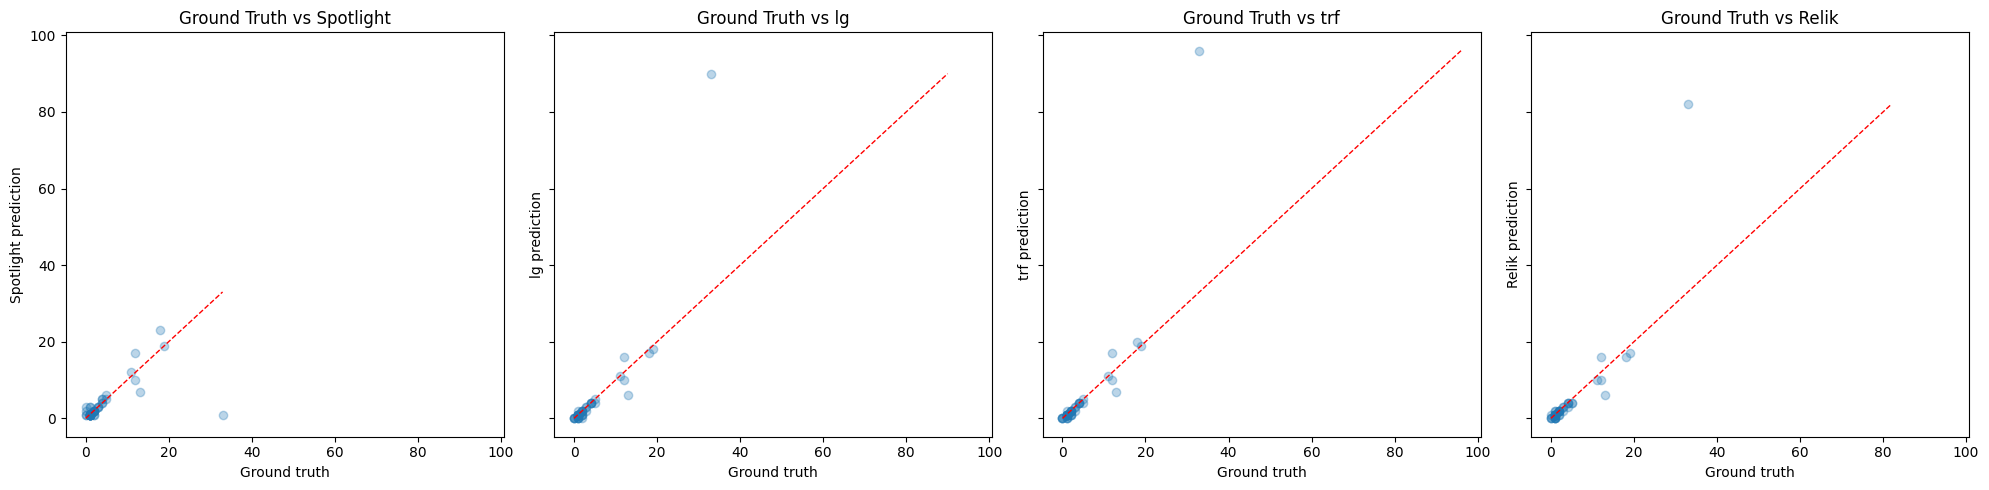

In [508]:
models = [
    ('spotlight_weight', 'Spotlight'),
    ('LG_weight', 'lg'),
    ('TRF_weight', 'trf'),
    ('relik_weight', 'Relik')
]

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharex=True, sharey=True)

for ax, (col, label) in zip(axes, models):
    ax.scatter(merged['GT_weight'], merged[col], alpha=0.3)

    lims = [
        min(merged['GT_weight'].min(), merged[col].min()),
        max(merged['GT_weight'].max(), merged[col].max())
    ]
    ax.plot(lims, lims, 'r--', linewidth=1)

    ax.set_xlabel('Ground truth')
    ax.set_ylabel(f'{label} prediction')
    ax.set_title(f'Ground Truth vs {label}')

plt.tight_layout()
plt.show()

### Log values

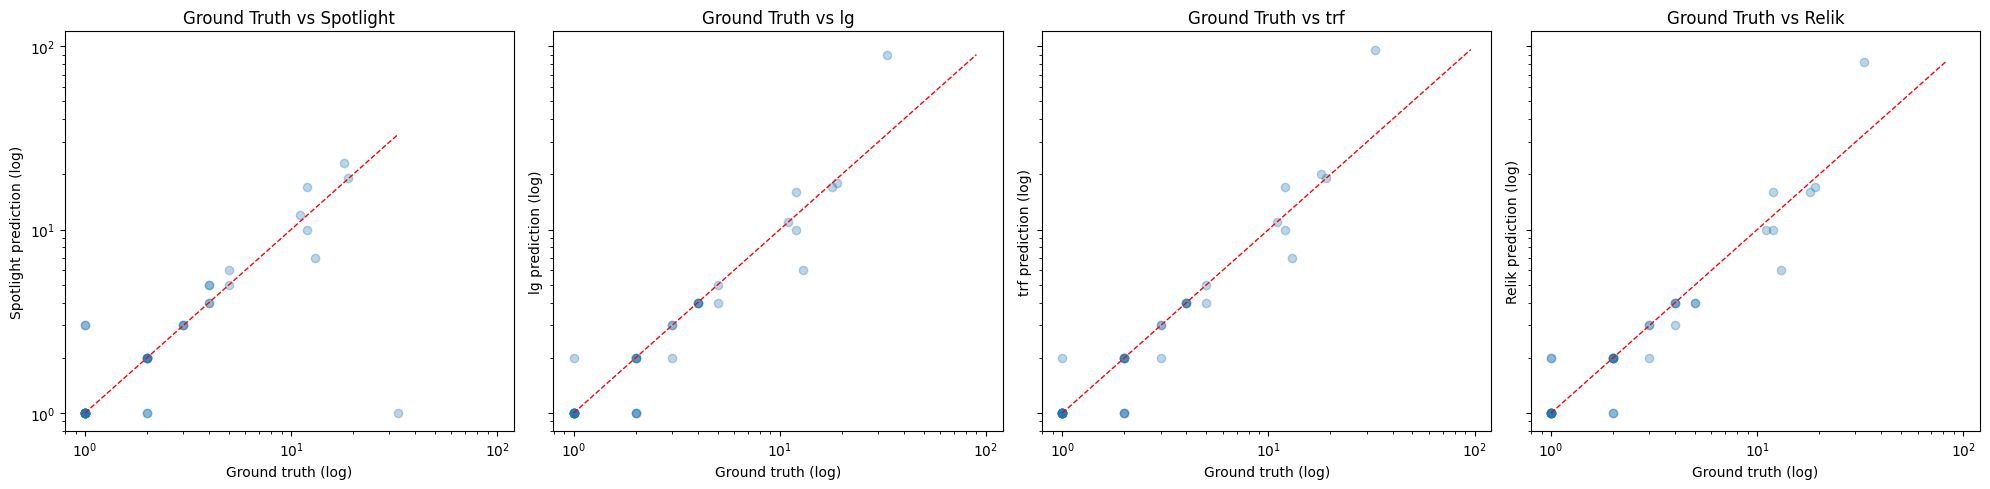

In [509]:
models = [
    ('spotlight_weight', 'Spotlight'),
    ('LG_weight', 'lg'),
    ('TRF_weight', 'trf'),
    ('relik_weight', 'Relik')
]

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharex=True, sharey=True)

for ax, (col, label) in zip(axes, models):
    # keep only rows where both values are > 0 (log can't show 0)
    data = merged[(merged['GT_weight'] > 0) & (merged[col] > 0)]

    ax.scatter(data['GT_weight'], data[col], alpha=0.3)

    lims = [
        min(data['GT_weight'].min(), data[col].min()),
        max(data['GT_weight'].max(), data[col].max())
    ]
    ax.plot(lims, lims, 'r--', linewidth=1)

    ax.set_xscale('log')
    ax.set_yscale('log')

    ax.set_xlabel('Ground truth (log)')
    ax.set_ylabel(f'{label} prediction (log)')
    ax.set_title(f'Ground Truth vs {label}')

plt.tight_layout()
plt.show()

In [510]:
models = [
    ('spotlight_weight', 'Spotlight'),
    ('LG_weight', 'lg'),
    ('TRF_weight', 'trf'),
    ('relik_weight', 'Relik')
]

print('Spearman Correlation:')

for (col, label) in models:
    spearman_corr = merged['GT_weight'].corr(merged[col], method='spearman')
    print(f"\t{label}:", round(spearman_corr, 3))


print('\nPearson Correlation:')

for col, label in models:
    pearson_corr = merged['GT_weight'].corr(merged[col], method='pearson')
    print(f"\t{label}:", round(pearson_corr, 3))

print('\nLog Pearson Correlation:')

for col, label in models:
    r_log = np.log1p(merged['GT_weight']).corr(np.log1p(merged[col]), method='pearson')
    print(f"\t{label}:", round(r_log, 3))

Spearman Correlation:
	Spotlight: 0.731
	lg: 0.901
	trf: 0.937
	Relik: 0.915

Pearson Correlation:
	Spotlight: 0.623
	lg: 0.879
	trf: 0.882
	Relik: 0.884

Log Pearson Correlation:
	Spotlight: 0.748
	lg: 0.94
	trf: 0.957
	Relik: 0.934


# With Napoleon's Outgoing Edges

In [511]:
models = [
    ('spotlight_weight', 'Spotlight'),
    ('LG_weight', 'lg'),
    ('TRF_weight', 'trf'),
    ('relik_weight', 'Relik'),
    ('relik_cie_weight', 'Relik_cie')
]

print('Spearman Correlation:')

for (col, label) in models:
    spearman_corr = final_merged['GT_weight'].corr(final_merged[col], method='spearman')
    print(f"\t{label}:", round(spearman_corr, 3))


print('\nPearson Correlation:')

for col, label in models:
    pearson_corr = final_merged['GT_weight'].corr(final_merged[col], method='pearson')
    print(f"\t{label}:", round(pearson_corr, 3))

print('\nLog Pearson Correlation:')

for col, label in models:
    r_log = np.log1p(final_merged['GT_weight']).corr(np.log1p(final_merged[col]), method='pearson')
    print(f"\t{label}:", round(r_log, 3))

Spearman Correlation:
	Spotlight: 0.826
	lg: 0.535
	trf: 0.536
	Relik: 0.832
	Relik_cie: 0.889

Pearson Correlation:
	Spotlight: 0.681
	lg: 0.279
	trf: 0.284
	Relik: 0.71
	Relik_cie: 0.632

Log Pearson Correlation:
	Spotlight: 0.789
	lg: 0.465
	trf: 0.465
	Relik: 0.831
	Relik_cie: 0.857


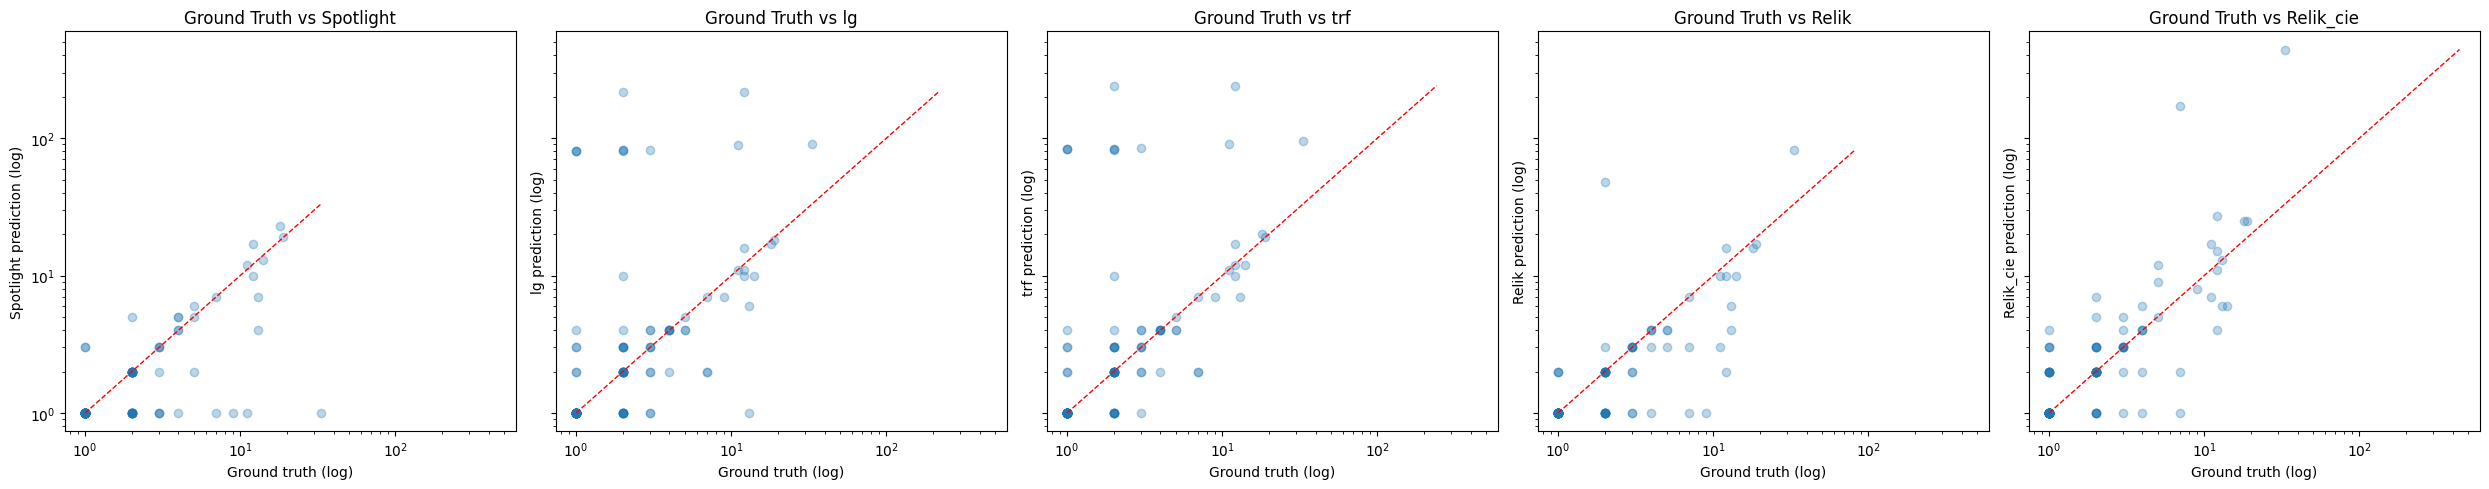

In [512]:
models = [
    ('spotlight_weight', 'Spotlight'),
    ('LG_weight', 'lg'),
    ('TRF_weight', 'trf'),
    ('relik_weight', 'Relik'),
    ('relik_cie_weight', 'Relik_cie')
]

fig, axes = plt.subplots(1, 5, figsize=(25, 5), sharex=True, sharey=True)

for ax, (col, label) in zip(axes, models):
    # keep only rows where both values are > 0 (log can't show 0)
    data = final_merged[(final_merged['GT_weight'] > 0) & (final_merged[col] > 0)]

    ax.scatter(data['GT_weight'], data[col], alpha=0.3)

    lims = [
        min(data['GT_weight'].min(), data[col].min()),
        max(data['GT_weight'].max(), data[col].max())
    ]
    ax.plot(lims, lims, 'r--', linewidth=1)

    ax.set_xscale('log')
    ax.set_yscale('log')

    ax.set_xlabel('Ground truth (log)')
    ax.set_ylabel(f'{label} prediction (log)')
    ax.set_title(f'Ground Truth vs {label}')

plt.tight_layout()
plt.show()

In [513]:
results = []
for col, label in models:
    data = final_merged[(final_merged['GT_weight'] > 0) & (final_merged[col] > 0)]

    log_gt   = np.log10(data['GT_weight'])
    log_pred = np.log10(data[col])

    err  = log_pred - log_gt
    mse  = np.mean(err ** 2)
    rmse = np.sqrt(mse)

    results.append({'model': label, 'n': len(data),
                    'log_MSE': mse, 'log_RMSE': rmse})

pd.DataFrame(results)

,model,n,log_MSE,log_RMSE
0,Spotlight,105,0.078692,0.280521
1,lg,114,0.286144,0.534924
2,trf,114,0.277399,0.526687
3,Relik,98,0.074923,0.273721
4,Relik_cie,118,0.074455,0.272865


In [514]:
# only napoleons outgoing edges
results = []
for col, label in models:
    data = merged_napoleon[(merged_napoleon['GT_weight'] > 0) & (merged_napoleon[col] > 0)]

    log_gt   = np.log10(data['GT_weight'])
    log_pred = np.log10(data[col])

    err  = log_pred - log_gt
    mse  = np.mean(err ** 2)
    rmse = np.sqrt(mse)

    results.append({'model': label, 'n': len(data),
                    'log_MSE': mse, 'log_RMSE': rmse})

pd.DataFrame(results)

,model,n,log_MSE,log_RMSE
0,Spotlight,63,0.082239,0.286773
1,lg,77,0.414180,0.643568
2,trf,75,0.412027,0.641893
3,Relik,61,0.108476,0.329357
4,Relik_cie,76,0.071262,0.266949


In [515]:
final_merged[final_merged['source_ID']=='Q7721']

,source_ID,target_ID,GT_weight,LG_weight,TRF_weight,relik_weight,relik_cie_weight,spotlight_weight
45,Q7721,Q517,33,90,96,82,442,1


In [519]:
final_merged[final_merged['relik_cie_weight']>15]

,source_ID,target_ID,GT_weight,LG_weight,TRF_weight,relik_weight,relik_cie_weight,spotlight_weight
4,Q68771,Q517,0,0,0,0,16,3
20,Q708011,Q517,18,17,20,16,25,23
29,Q53444,Q517,19,18,19,17,25,19
31,Q356933,Q517,11,11,11,10,17,12
40,Q5547,Q517,12,16,17,16,27,17
45,Q7721,Q517,33,90,96,82,442,1
127,Q517,Q131691,7,2,2,3,172,0


# OTHER PLOTS

In [517]:
plt.figure(figsize=(12, 5))
plt.bar(merged['ID'], merged['GT_weight'], label='Ground truth', color = 'grey', alpha=0.3)
plt.scatter(merged['ID'], merged['spotlight_weight'], label='Spotligt', color = 'green', alpha=0.5)
plt.scatter(merged['ID'], merged['LG_weight'], label='lg', color = 'red', alpha=0.5)
plt.scatter(merged['ID'], merged['TRF_weight'], label='trf', color = 'blue', alpha=0.5)

plt.xlabel('ID')
plt.ylabel('weight')
plt.xticks([])
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

KeyError: 'ID'

<Figure size 1200x500 with 0 Axes>

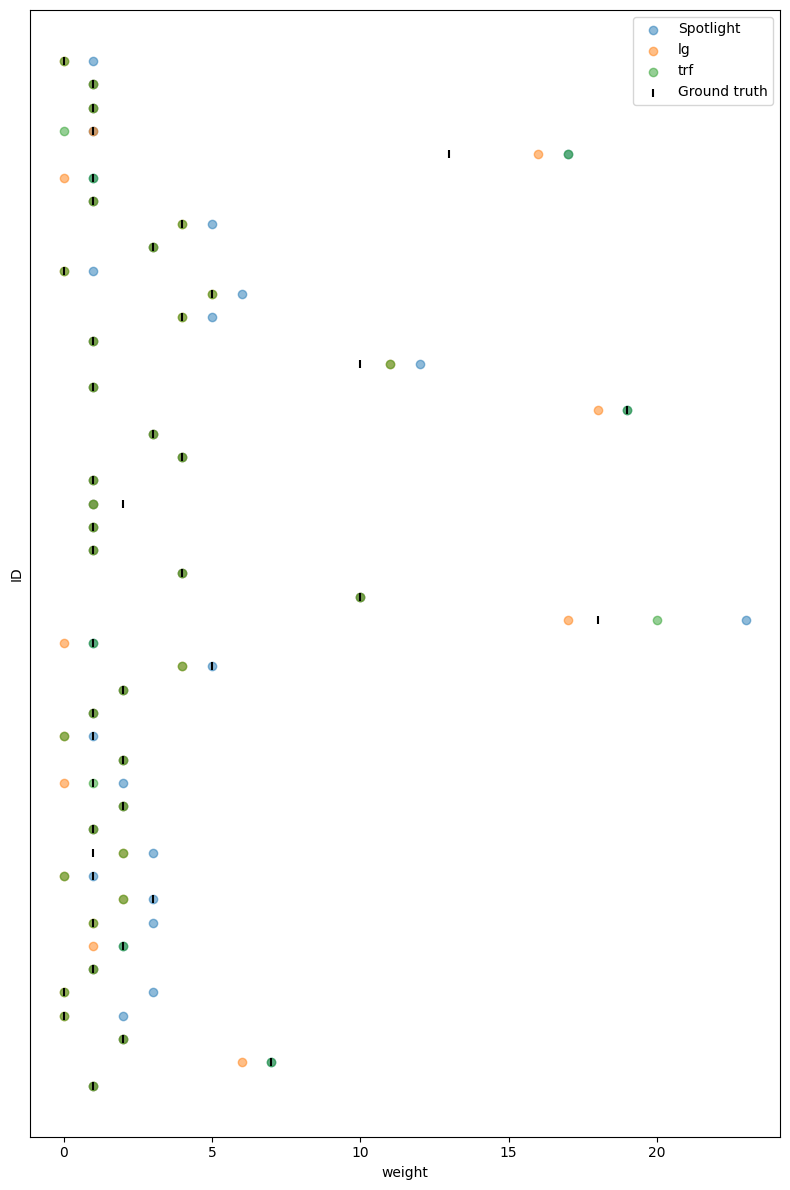

In [ ]:
plt.figure(figsize=(8, 12))
plt.scatter(merged['spotlight_weight'], merged['ID'], label='Spotlight', alpha=0.5)
plt.scatter(merged['LG_weight'], merged['ID'], label='lg', alpha=0.5)
plt.scatter(merged['TRF_weight'], merged['ID'], label='trf', alpha=0.5)
plt.scatter(merged['GT_weight'], merged['ID'], label='Ground truth', alpha=1, color='black', marker='|')

plt.xlabel('weight')
plt.ylabel('ID')
plt.yticks([])
plt.legend()
plt.tight_layout()
plt.show()

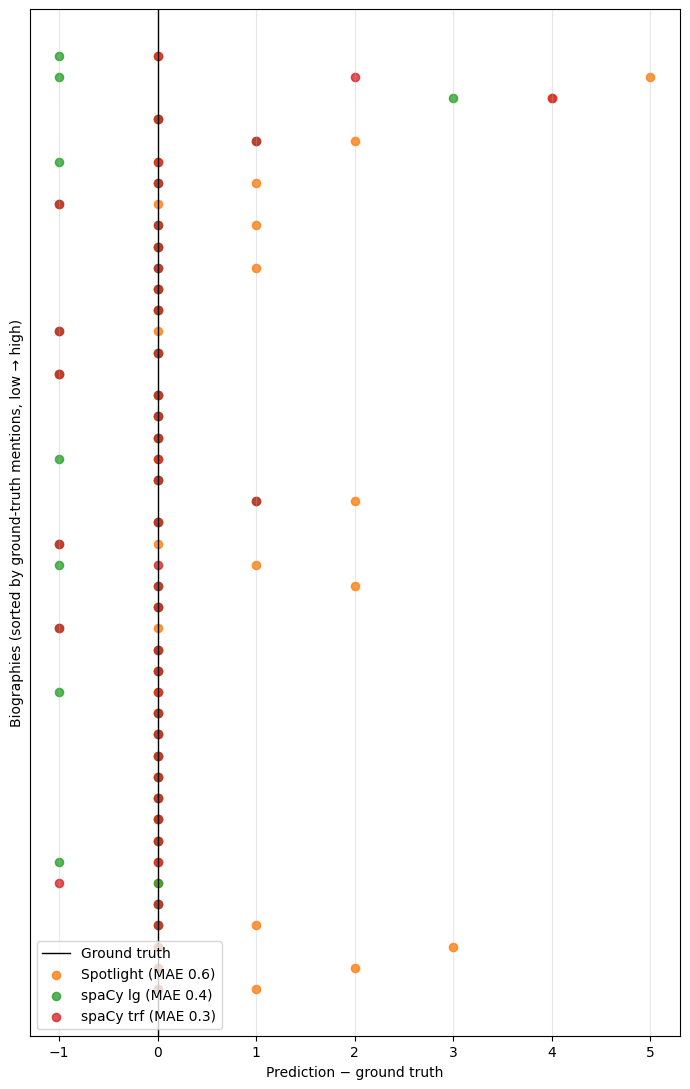

In [ ]:
df = merged.sort_values('GT_weight').reset_index(drop=True)
y = np.arange(len(df))

models = [
    ('spotlight_weight', 'Spotlight', 'tab:orange',   'o'),
    ('LG_weight',        'spaCy lg',  'tab:green', 'o'),
    ('TRF_weight',       'spaCy trf', 'tab:red',  'o'),
]

fig, ax = plt.subplots(figsize=(7, 11))
ax.axvline(0, color='black', linewidth=1, label='Ground truth')

for col, label, color, marker in models:
    err = df[col] - df['GT_weight']
    ax.scatter(err, y, color=color, marker=marker, s=35, alpha=0.8,
               label=f'{label} (MAE {err.abs().mean():.1f})')

ax.set_yticks([])
ax.set_ylabel('Biographies (sorted by ground-truth mentions, low → high)')
ax.set_xlabel('Prediction − ground truth')
ax.grid(axis='x', alpha=0.3)
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

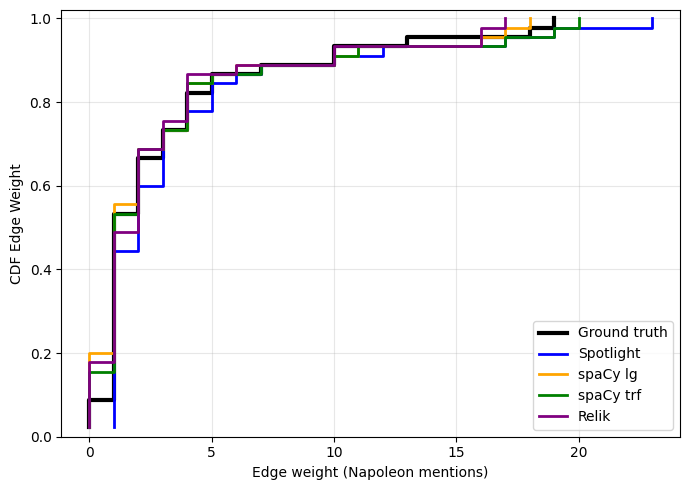

In [ ]:
cols = [
    ('GT_weight',        'Ground truth', 'black'),
    ('spotlight_weight', 'Spotlight',    'blue'),
    ('LG_weight',        'spaCy lg',     'orange'),
    ('TRF_weight',       'spaCy trf',    'green'),
    ('relik_weight',     'Relik',        'purple')
]

fig, ax = plt.subplots(figsize=(7, 5))

for col, label, color in cols:
    x = np.sort(merged[col])
    y = np.arange(1, len(x) + 1) / len(x)
    ax.step(x, y, where='post', label=label, color=color,
            linewidth=3 if col == 'GT_weight' else 2)

ax.set_xlabel('Edge weight (Napoleon mentions)')
ax.set_ylabel('CDF Edge Weight')
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()